# Part 2: Question 1, Predicting 30-Day Readmission

**Data science project: Predicting 30-Day Hospital Readmission for Patients with Diabetes**

**Name:** Bernard Issifu

**Question 1.** Which patient and hospital-stay factors best predict readmission within 30 days?

This notebook trains and compares three classifiers on the cleaned data from Part 1 (run
`01_data_preparation_eda.ipynb` first). The R version is `r/02_q1_classification.Rmd`.

In [1]:
# ---- Setup ----
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, average_precision_score, recall_score, precision_score,
                             f1_score, confusion_matrix, roc_curve)

sns.set_theme(style="whitegrid")
FIG_DIR = "../report/figures"
os.makedirs(FIG_DIR, exist_ok=True)

# keep_default_na=False keeps the 'None' test category as text
df = pd.read_csv("../data/processed/diabetes_clean_python.csv", keep_default_na=False)
print(df.shape)
print(f"30-day readmission rate: {df['readmit_30'].mean():.2%}")

(69987, 47)
30-day readmission rate: 8.98%


---
# 1. Approach

**Features.** 25 predictors describing the patient and the stay:

- *Numeric:* age, length of stay, numbers of lab procedures, procedures, medications and diagnoses, and
  number of medication changes. These are standardized (z-score) so the logistic regression
  coefficients are comparable.
- *Skewed counts:* prior-year outpatient, emergency and inpatient visits. Most patients have zero and a
  few have dozens, so they are log-transformed (`log(x + 1)`) before standardizing.
- *Categorical:* race, gender, admission type and source, discharge destination, medical specialty,
  the three diagnosis groups, both glucose tests, insulin and metformin status, medication change and
  whether any diabetes medication was prescribed. These are one-hot encoded with a dropped reference
  level.

**Imbalance.** Only 8.98% of patients are readmitted, so a model that always predicts "no" would be 91%
accurate and useless. Each model therefore weights the classes inversely to their frequency
(`class_weight="balanced"`), and accuracy is not used. Models are judged by:

- **ROC-AUC:** how well the model ranks readmitted patients above others (0.5 = chance, 1 = perfect);
- **Recall:** the share of readmitted patients the model flags;
- **Precision:** the share of flagged patients who were actually readmitted (the base rate is 9%).

**Models.**

- **Logistic regression:** a transparent baseline whose coefficients show each factor's direction and
  size of effect.
- **Decision tree:** limited to depth 6 and at least 100 patients per leaf, so it stays readable and
  does not overfit.
- **Random forest:** 300 trees with at least 20 patients per leaf; it captures interactions and
  non-linear effects the other two miss.

The data are split **80/20 with stratification on the outcome**, so both sets keep the 8.98% rate. The
training set is also used for **5-fold cross-validation** to check that the comparison is stable.

In [2]:
num_cols = ["age_years", "time_in_hospital", "num_lab_procedures", "num_procedures",
            "num_medications", "number_diagnoses", "n_med_changes"]
skew_cols = ["number_outpatient", "number_emergency", "number_inpatient"]
cat_cols = ["race", "gender", "admission_type", "discharge_to", "admission_source",
            "medical_specialty", "diag1_group", "diag2_group", "diag3_group", "A1Cresult",
            "max_glu_serum", "insulin", "metformin", "change", "diabetesMed"]

X = df[num_cols + skew_cols + cat_cols]
y = df["readmit_30"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(f"Training: {len(X_train):,} patients ({y_train.mean():.2%} readmitted)")
print(f"Test:     {len(X_test):,} patients ({y_test.mean():.2%} readmitted)")

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("skew", Pipeline([("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")), ("scale", StandardScaler())]), skew_cols),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols),
])

Training: 55,989 patients (8.98% readmitted)
Test:     13,998 patients (8.98% readmitted)


---
# 2. Training and evaluation

In [3]:
models = {
    "Logistic regression": LogisticRegression(class_weight="balanced", max_iter=2000),
    "Decision tree": DecisionTreeClassifier(max_depth=6, min_samples_leaf=100,
                                            class_weight="balanced", random_state=42),
    "Random forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=20,
                                            class_weight="balanced_subsample", n_jobs=-1,
                                            random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
fitted, rows, probs = {}, [], {}
for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    cv_auc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    pipe.fit(X_train, y_train)
    p = pipe.predict_proba(X_test)[:, 1]
    pred = (p >= 0.5).astype(int)
    fitted[name], probs[name] = pipe, p
    rows.append({"model": name,
                 "CV ROC-AUC (mean ± sd)": f"{cv_auc.mean():.3f} ± {cv_auc.std():.3f}",
                 "Test ROC-AUC": roc_auc_score(y_test, p),
                 "Test PR-AUC": average_precision_score(y_test, p),
                 "Recall": recall_score(y_test, pred),
                 "Precision": precision_score(y_test, pred),
                 "F1": f1_score(y_test, pred),
                 "Share flagged": pred.mean()})

results = pd.DataFrame(rows).set_index("model").round(3)
results

,CV ROC-AUC (mean ± sd),Test ROC-AUC,Test PR-AUC,Recall,Precision,F1,Share flagged
model,,,,,,,
Logistic regression,0.639 ± 0.004,0.640,0.153,0.539,0.135,0.216,0.359
Decision tree,0.627 ± 0.006,0.634,0.146,0.567,0.129,0.210,0.395
Random forest,0.646 ± 0.007,0.647,0.159,0.348,0.165,0.224,0.190


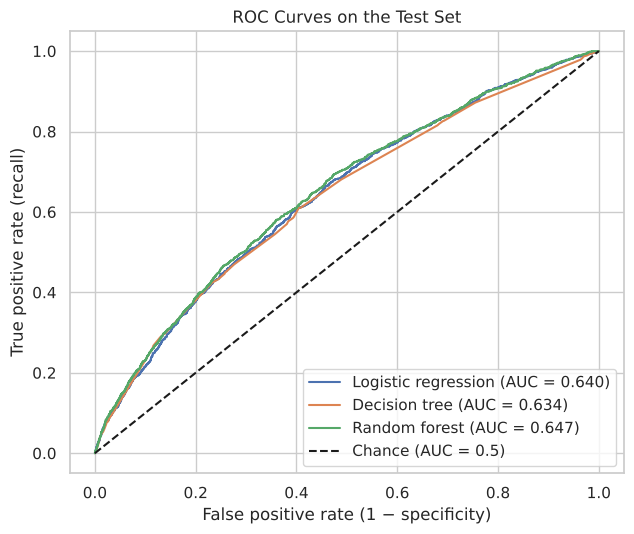

In [4]:
# ROC curves on the test set
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    ax.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, p):.3f})")
ax.plot([0, 1], [0, 1], "k--", label="Chance (AUC = 0.5)")
ax.set_title("ROC Curves on the Test Set")
ax.set_xlabel("False positive rate (1 − specificity)")
ax.set_ylabel("True positive rate (recall)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/q1_roc_curves.png", dpi=150)
plt.show()

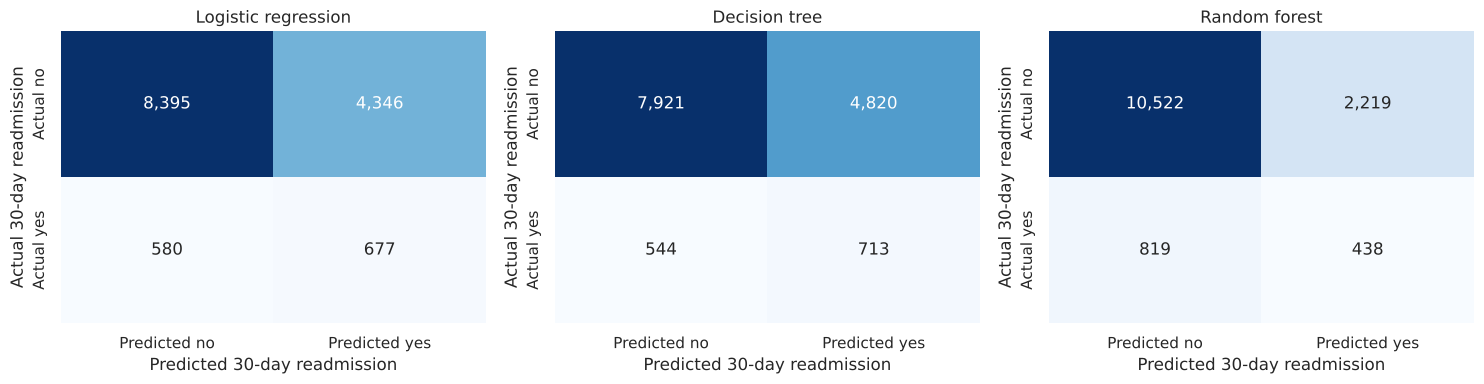

In [5]:
# Confusion matrices at the default 0.5 threshold
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, p) in zip(axes, probs.items()):
    cm = confusion_matrix(y_test, (p >= 0.5).astype(int))
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Predicted no", "Predicted yes"],
                yticklabels=["Actual no", "Actual yes"])
    ax.set_title(f"{name}")
    ax.set_xlabel("Predicted 30-day readmission")
    ax.set_ylabel("Actual 30-day readmission")
plt.tight_layout()
plt.show()

**Interpretation.** All three models rank patients better than chance, with test ROC-AUC between
about 0.63 and 0.65; the cross-validated AUCs on the training data are similar, so the comparison is
stable. The random forest ranks best, but the gain over the logistic regression is small. At the 0.5
threshold, the logistic regression and decision tree flag over a third of patients and catch over half
of the readmissions, while the random forest is more selective: it flags about a fifth of patients with
higher precision (about 16–17% of flagged patients are readmitted, against a 9% base rate) but lower
recall. Precision stays low for every model: readmission depends heavily on what happens after
discharge, which this dataset does not record.

---
# 3. Which factors matter?

## 3.1 Logistic regression: odds ratios

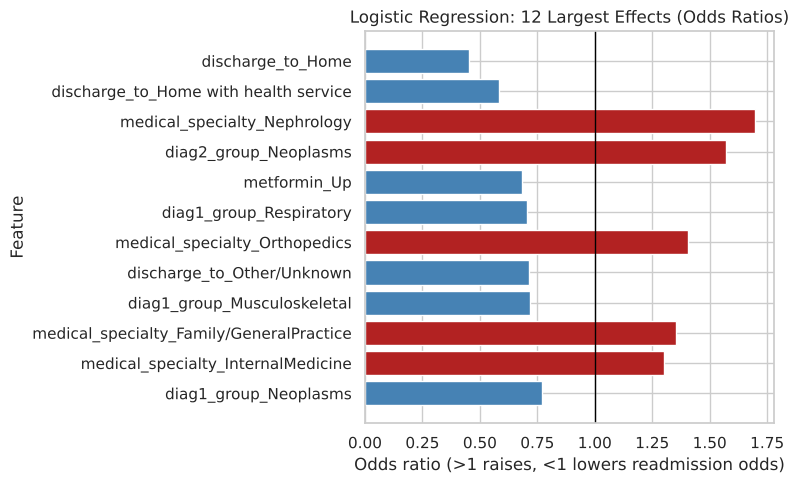

,coefficient,odds_ratio
discharge_to_Home,-0.794,0.452
discharge_to_Home with health service,-0.542,0.581
medical_specialty_Nephrology,0.528,1.695
diag2_group_Neoplasms,0.451,1.570
metformin_Up,-0.380,0.684
diag1_group_Respiratory,-0.351,0.704
medical_specialty_Orthopedics,0.340,1.405
discharge_to_Other/Unknown,-0.339,0.712
diag1_group_Musculoskeletal,-0.332,0.718
medical_specialty_Family/GeneralPractice,0.301,1.352


In [6]:
lr = fitted["Logistic regression"]
names = lr.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(lr.named_steps["model"].coef_[0], index=names)
odds = pd.DataFrame({"coefficient": coefs, "odds_ratio": np.exp(coefs)})
odds.index = (odds.index.str.replace("num__", "").str.replace("skew__", "log ")
              .str.replace("cat__", ""))
top = odds.reindex(odds["coefficient"].abs().sort_values(ascending=False).index).head(12)

fig, ax = plt.subplots(figsize=(8, 5))
colors = ["firebrick" if v > 1 else "steelblue" for v in top["odds_ratio"]]
ax.barh(top.index[::-1], top["odds_ratio"][::-1], color=colors[::-1])
ax.axvline(1, color="black", lw=1)
ax.set_title("Logistic Regression: 12 Largest Effects (Odds Ratios)")
ax.set_xlabel("Odds ratio (>1 raises, <1 lowers readmission odds)")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/q1_odds_ratios.png", dpi=150)
plt.show()

top.round(3)

Numeric odds ratios are per one standard deviation (or per one standard deviation of `log(x + 1)` for
the visit counts); categorical ones compare against the dropped reference level.

## 3.2 Random forest: permutation importance

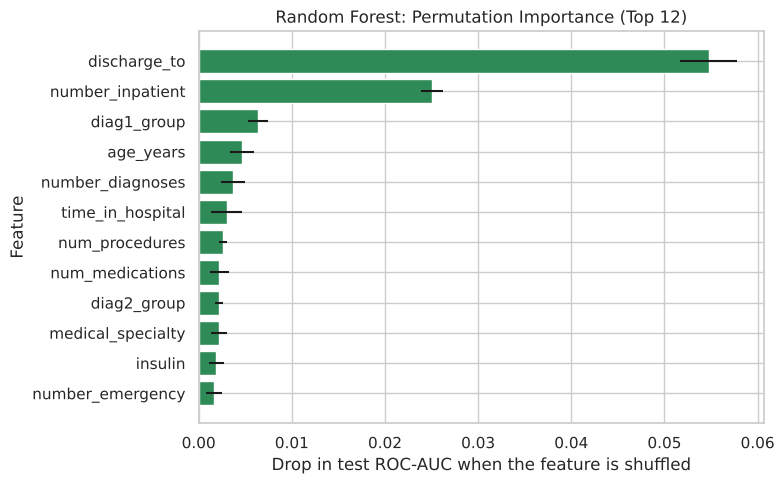

,mean_auc_drop,sd
discharge_to,0.0547,0.0030
number_inpatient,0.0250,0.0012
diag1_group,0.0064,0.0010
age_years,0.0046,0.0013
number_diagnoses,0.0037,0.0013
time_in_hospital,0.0030,0.0016
num_procedures,0.0026,0.0004
num_medications,0.0022,0.0010
diag2_group,0.0022,0.0004
medical_specialty,0.0022,0.0008


In [7]:
# Permutation importance: how much the test ROC-AUC drops when one feature's values are shuffled.
# Computed on the original columns, so each categorical variable counts once.
rf = fitted["Random forest"]
perm = permutation_importance(rf, X_test, y_test, scoring="roc_auc", n_repeats=5,
                              random_state=42, n_jobs=-1)
imp = pd.DataFrame({"mean_auc_drop": perm.importances_mean, "sd": perm.importances_std},
                   index=X_test.columns).sort_values("mean_auc_drop", ascending=False)

top_imp = imp.head(12)
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top_imp.index[::-1], top_imp["mean_auc_drop"][::-1], xerr=top_imp["sd"][::-1],
        color="seagreen")
ax.set_title("Random Forest: Permutation Importance (Top 12)")
ax.set_xlabel("Drop in test ROC-AUC when the feature is shuffled")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/q1_permutation_importance.png", dpi=150)
plt.show()

imp.round(4).head(12)

## 3.3 Decision tree: the top splits

The thresholds are on the transformed scale (standardized, and log-transformed for visit counts), and
one-hot columns are 0/1, so `discharge_to_Home <= 0.50` means "not discharged home".

In [8]:
from sklearn.tree import export_text
tree = fitted["Decision tree"]
tree_names = [n.replace("num__", "").replace("skew__", "log_").replace("cat__", "")
              for n in tree.named_steps["prep"].get_feature_names_out()]
print(export_text(tree.named_steps["model"], feature_names=tree_names, max_depth=2))

|--- discharge_to_Home <= 0.50
|   |--- log_number_inpatient <= 0.83
|   |   |--- discharge_to_Home with health service <= 0.50
|   |   |   |--- truncated branch of depth 4
|   |   |--- discharge_to_Home with health service >  0.50
|   |   |   |--- truncated branch of depth 4
|   |--- log_number_inpatient >  0.83
|   |   |--- discharge_to_Home with health service <= 0.50
|   |   |   |--- truncated branch of depth 4
|   |   |--- discharge_to_Home with health service >  0.50
|   |   |   |--- truncated branch of depth 4
|--- discharge_to_Home >  0.50
|   |--- log_number_inpatient <= 0.83
|   |   |--- time_in_hospital <= 0.42
|   |   |   |--- truncated branch of depth 4
|   |   |--- time_in_hospital >  0.42
|   |   |   |--- truncated branch of depth 4
|   |--- log_number_inpatient >  0.83
|   |   |--- log_number_inpatient <= 3.85
|   |   |   |--- truncated branch of depth 4
|   |   |--- log_number_inpatient >  3.85
|   |   |   |--- truncated branch of depth 3



In [9]:
# Save results for the report
results.to_csv(f"{FIG_DIR}/q1_results_python.csv")
imp.to_csv(f"{FIG_DIR}/q1_permutation_importance_python.csv")
top.to_csv(f"{FIG_DIR}/q1_odds_ratios_python.csv")

---
# 4. Discussion

**What predicts early readmission?** Two factors stand out, and all three models agree on them.

1. **Discharge destination** is by far the strongest predictor. Shuffling it lowers the random
   forest's test AUC by 0.055, more than twice any other feature; it is the first split of the decision
   tree; and in the logistic regression, patients discharged home have **0.45 times the odds** of
   30-day readmission of patients discharged to a care facility (0.58 times when sent home with health
   services). Patients who need a care facility are sicker and frailer at discharge.
2. **Prior inpatient visits** come second: each standard deviation of `log(visits + 1)` raises the odds
   by 24% (odds ratio 1.24), it is the tree's second split, and it is second in permutation importance.
   Patients who were hospitalized in the past year are more likely to return.

Smaller but consistent effects come from age, length of stay, number of diagnoses and emergency visits
(each about 7% higher odds per standard deviation), being on any diabetes medication (odds ratio 1.28),
and some admitting specialties (nephrology patients, often with kidney disease, have 1.7 times the odds
of cardiology patients). Patients whose HbA1c was **never tested** have slightly higher odds (1.13)
than those with a high result, in line with Strack et al.'s finding that measuring HbA1c is associated
with fewer readmissions, but the effect is small here.

**How useful are the models?** Performance is modest: a test ROC-AUC of 0.65 means the best model ranks
a randomly chosen readmitted patient above a non-readmitted one about 65% of the time. In practical
terms, the random forest flags 19% of patients and catches 35% of the readmissions, with a precision of
16.5%, almost twice the 9% base rate. That could help a hospital target follow-up calls or discharge
planning, but it would miss most readmissions. The ceiling is likely set by the data rather than the
models: readmission depends on what happens after discharge (medication adherence, follow-up visits,
home support), none of which is recorded, and the more flexible random forest gains little over the
logistic regression.

**Limitations.** The data come from 1999–2008, only each patient's first stay is used, and the results
use the default 0.5 threshold; a hospital would choose its own threshold to trade recall against
workload.